# Sales Data Analysis using Pandas, NumPy and Matplotlib



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = {
    "OrderID": [1001,1002,1003,1004,1005,1006,1007,1008,1009,1010,1011,1012,1013,1014,1015,1016,1017,1018,1019,1020],
    "OrderDate": ["2025-01-05","2025-01-08","2025-01-12","2025-01-18","2025-02-03","2025-02-07","2025-02-14","2025-02-21","2025-03-02","2025-03-09","2025-03-15","2025-03-22","2025-04-04","2025-04-11","2025-04-19","2025-05-06","2025-05-13","2025-05-20","2025-06-03","2025-06-17"],
    "Region": ["North","South","East","West","South","North","East","West","North","South","East","West","North","South","East","West","North","South","East","West"],
    "Category": ["Electronics","Furniture","Office Supplies","Electronics","Electronics","Furniture","Electronics","Office Supplies","Electronics","Furniture","Office Supplies","Electronics","Furniture","Electronics","Office Supplies","Furniture","Electronics","Office Supplies","Electronics","Furniture"],
    "Product": ["Laptop","Chair","Printer Paper","Headphones","Monitor","Desk","Keyboard","Notebook","Mouse","Bookshelf","Stapler","Tablet","Office Chair","Smartphone","File Folder","Table","Smartwatch","Marker Set","Camera","Cabinet"],
    "Quantity": [2,5,10,4,3,2,6,20,8,3,12,2,4,3,25,2,5,15,2,3],
    "UnitPrice": [65000,4500,550,2200,14500,9000,1800,180,900,7200,350,28000,6500,24000,120,11000,6500,250,42000,8500],
    "Sales": [130000,22500,5500,8800,43500,18000,10800,3600,7200,21600,4200,56000,26000,72000,3000,22000,32500,3750,84000,25500],
    "Discount": [5,10,0,5,8,5,0,2,5,10,0,7,5,10,0,5,8,2,6,10],
    "Profit": [18000,5000,1200,1800,6500,3200,2200,900,1500,3600,900,8500,5200,11000,700,4000,5500,800,12500,4300]
}

df = pd.DataFrame(data)
df.to_csv("sales_dataset_20_rows.csv", index=False)
df.head()

,OrderID,OrderDate,Region,Category,Product,Quantity,UnitPrice,Sales,Discount,Profit
0,1001,2025-01-05,North,Electronics,Laptop,2,65000,130000,5,18000
1,1002,2025-01-08,South,Furniture,Chair,5,4500,22500,10,5000
2,1003,2025-01-12,East,Office Supplies,Printer Paper,10,550,5500,0,1200
3,1004,2025-01-18,West,Electronics,Headphones,4,2200,8800,5,1800
4,1005,2025-02-03,South,Electronics,Monitor,3,14500,43500,8,6500


In [ ]:
df = pd.read_csv("sales_dataset_20_rows.csv")
df

In [3]:
df.shape

(20, 10)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   OrderID    20 non-null     int64
 1   OrderDate  20 non-null     str  
 2   Region     20 non-null     str  
 3   Category   20 non-null     str  
 4   Product    20 non-null     str  
 5   Quantity   20 non-null     int64
 6   UnitPrice  20 non-null     int64
 7   Sales      20 non-null     int64
 8   Discount   20 non-null     int64
 9   Profit     20 non-null     int64
dtypes: int64(6), str(4)
memory usage: 1.7 KB


In [5]:
df.describe()

,OrderID,Quantity,UnitPrice,Sales,Discount,Profit
count,20.00000,20.000000,20.00000,20.00000,20.000000,20.000000
mean,1010.50000,6.800000,11652.50000,30022.50000,5.150000,4865.000000
std,5.91608,6.517991,16676.32923,32954.81945,3.558163,4570.416888
min,1001.00000,2.000000,120.00000,3000.00000,0.000000,700.000000
25%,1005.75000,2.750000,812.50000,6775.00000,2.000000,1425.000000
50%,1010.50000,4.000000,6500.00000,21800.00000,5.000000,3800.000000
75%,1015.25000,8.500000,11875.00000,35250.00000,8.000000,5750.000000
max,1020.00000,25.000000,65000.00000,130000.00000,10.000000,18000.000000


## Aggregate Functions

In [6]:
df["Sales"].sum()

np.int64(600450)

In [7]:
df["Sales"].mean()

np.float64(30022.5)

In [8]:
df["Sales"].min()

np.int64(3000)

In [9]:
df["Sales"].max()

np.int64(130000)

In [10]:
df["Sales"].count()

np.int64(20)

In [11]:
df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

Region
North    213700
South    163350
West     115900
East     107500
Name: Sales, dtype: int64

In [12]:
df.groupby("Region")["Sales"].agg(["sum","mean","min","max","count"])

,sum,mean,min,max,count
Region,,,,,
East,107500,21500.0,3000,84000,5
North,213700,42740.0,7200,130000,5
South,163350,32670.0,3750,72000,5
West,115900,23180.0,3600,56000,5


In [13]:
df.groupby("Category").agg({"Sales":["sum","mean"],"Quantity":"sum","Profit":"sum"}).sort_values(("Sales","sum"), ascending=False)

Sales               Quantity Profit
                    sum          mean      sum    sum
Category                                             
Electronics      444800  49422.222222       35  67500
Furniture        135600  22600.000000       19  25300
Office Supplies   20050   4010.000000       82   4500

## Create New Columns

In [14]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100
df["Sales_Per_Unit"] = df["Sales"] / df["Quantity"]
df.head()

,OrderID,OrderDate,Region,Category,Product,Quantity,UnitPrice,Sales,Discount,Profit,Revenue,Profit_Margin,Sales_Per_Unit
0,1001,2025-01-05,North,Electronics,Laptop,2,65000,130000,5,18000,130000,13.846154,65000.0
1,1002,2025-01-08,South,Furniture,Chair,5,4500,22500,10,5000,22500,22.222222,4500.0
2,1003,2025-01-12,East,Office Supplies,Printer Paper,10,550,5500,0,1200,5500,21.818182,550.0
3,1004,2025-01-18,West,Electronics,Headphones,4,2200,8800,5,1800,8800,20.454545,2200.0
4,1005,2025-02-03,South,Electronics,Monitor,3,14500,43500,8,6500,43500,14.942529,14500.0


In [15]:
df[["OrderID","Quantity","UnitPrice","Sales","Revenue","Profit_Margin","Sales_Per_Unit"]]

,OrderID,Quantity,UnitPrice,Sales,Revenue,Profit_Margin,Sales_Per_Unit
0,1001,2,65000,130000,130000,13.846154,65000.0
1,1002,5,4500,22500,22500,22.222222,4500.0
2,1003,10,550,5500,5500,21.818182,550.0
3,1004,4,2200,8800,8800,20.454545,2200.0
4,1005,3,14500,43500,43500,14.942529,14500.0
5,1006,2,9000,18000,18000,17.777778,9000.0
6,1007,6,1800,10800,10800,20.370370,1800.0
7,1008,20,180,3600,3600,25.000000,180.0
8,1009,8,900,7200,7200,20.833333,900.0
9,1010,3,7200,21600,21600,16.666667,7200.0


## Data Comparison and Filtering

In [16]:
df.sort_values("Sales", ascending=False)[["OrderID","Region","Category","Product","Sales","Profit"]].head(5)

,OrderID,Region,Category,Product,Sales,Profit
0,1001,North,Electronics,Laptop,130000,18000
18,1019,East,Electronics,Camera,84000,12500
13,1014,South,Electronics,Smartphone,72000,11000
11,1012,West,Electronics,Tablet,56000,8500
4,1005,South,Electronics,Monitor,43500,6500


In [17]:
df[df["Sales"] > df["Sales"].mean()][["OrderID","Region","Product","Sales"]]

,OrderID,Region,Product,Sales
0,1001,North,Laptop,130000
4,1005,South,Monitor,43500
11,1012,West,Tablet,56000
13,1014,South,Smartphone,72000
16,1017,North,Smartwatch,32500
18,1019,East,Camera,84000


In [18]:
df[df["Profit"] == df["Profit"].max()][["OrderID","Product","Sales","Profit"]]

,OrderID,Product,Sales,Profit
0,1001,Laptop,130000,18000


In [19]:
df.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(10)

Product
Laptop          130000
Camera           84000
Smartphone       72000
Tablet           56000
Monitor          43500
Smartwatch       32500
Office Chair     26000
Cabinet          25500
Chair            22500
Table            22000
Name: Sales, dtype: int64

In [20]:
df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

Region
North    33400
South    26900
West     19500
East     17500
Name: Profit, dtype: int64

In [21]:
df[df["Category"] == "Electronics"][["OrderID","Product","Sales","Profit"]]

,OrderID,Product,Sales,Profit
0,1001,Laptop,130000,18000
3,1004,Headphones,8800,1800
4,1005,Monitor,43500,6500
6,1007,Keyboard,10800,2200
8,1009,Mouse,7200,1500
11,1012,Tablet,56000,8500
13,1014,Smartphone,72000,11000
16,1017,Smartwatch,32500,5500
18,1019,Camera,84000,12500


## DateTime Conversion

In [22]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"])
df.dtypes

OrderID                    int64
OrderDate         datetime64[us]
Region                       str
Category                     str
Product                      str
Quantity                   int64
UnitPrice                  int64
Sales                      int64
Discount                   int64
Profit                     int64
Revenue                    int64
Profit_Margin            float64
Sales_Per_Unit           float64
dtype: object

In [23]:
df["Year"] = df["OrderDate"].dt.year
df["Month"] = df["OrderDate"].dt.month
df["Month_Name"] = df["OrderDate"].dt.month_name()
df["Day"] = df["OrderDate"].dt.day
df["Day_Name"] = df["OrderDate"].dt.day_name()

df[["OrderID","OrderDate","Year","Month","Month_Name","Day","Day_Name"]]

,OrderID,OrderDate,Year,Month,Month_Name,Day,Day_Name
0,1001,2025-01-05,2025,1,January,5,Sunday
1,1002,2025-01-08,2025,1,January,8,Wednesday
2,1003,2025-01-12,2025,1,January,12,Sunday
3,1004,2025-01-18,2025,1,January,18,Saturday
4,1005,2025-02-03,2025,2,February,3,Monday
5,1006,2025-02-07,2025,2,February,7,Friday
6,1007,2025-02-14,2025,2,February,14,Friday
7,1008,2025-02-21,2025,2,February,21,Friday
8,1009,2025-03-02,2025,3,March,2,Sunday
9,1010,2025-03-09,2025,3,March,9,Sunday


## Date-Based Analysis

In [24]:
df.groupby("Year")["Sales"].sum()

Year
2025    600450
Name: Sales, dtype: int64

In [25]:
df.groupby(["Year","Month"])["Sales"].sum()

Year  Month
2025  1        166800
      2         75900
      3         89000
      4        101000
      5         58250
      6        109500
Name: Sales, dtype: int64

In [26]:
df.groupby("Month_Name")["Sales"].sum().reindex(df["Month_Name"].drop_duplicates())

Month_Name
January     166800
February     75900
March        89000
April       101000
May          58250
June        109500
Name: Sales, dtype: int64

In [27]:
df.groupby("Day_Name")["Sales"].sum()

Day_Name
Friday       130400
Monday        43500
Saturday      72000
Sunday       164300
Tuesday      167750
Wednesday     22500
Name: Sales, dtype: int64

## Matplotlib Charts

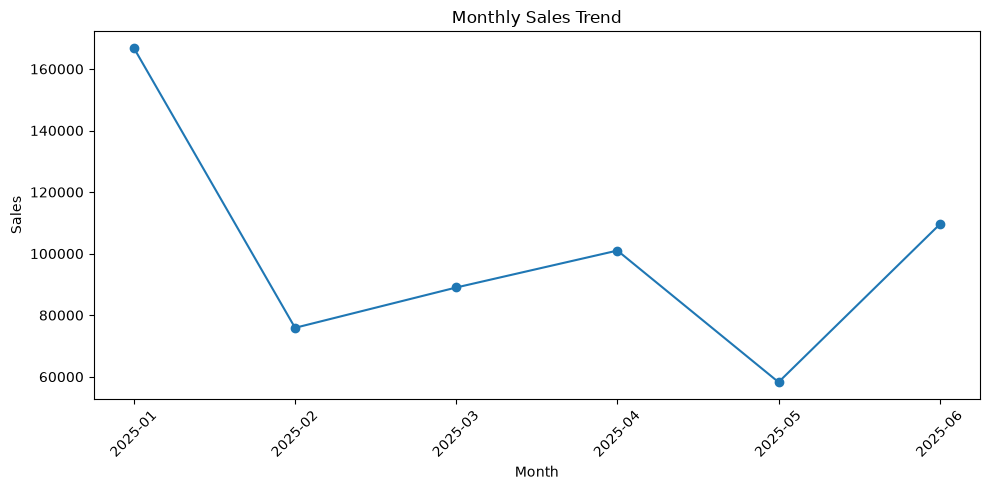

In [28]:
monthly_sales = df.groupby(df["OrderDate"].dt.to_period("M"))["Sales"].sum()

plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Monthly Sales Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

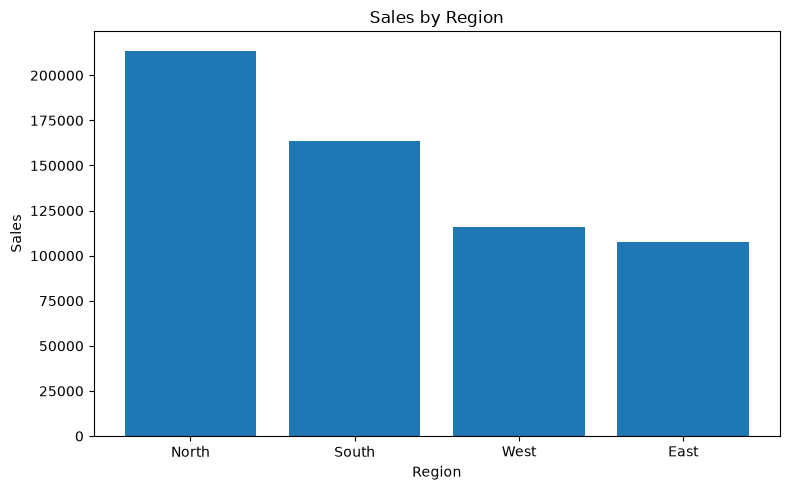

In [29]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
plt.bar(region_sales.index, region_sales.values)
plt.xlabel("Region")
plt.ylabel("Sales")
plt.title("Sales by Region")
plt.tight_layout()
plt.show()

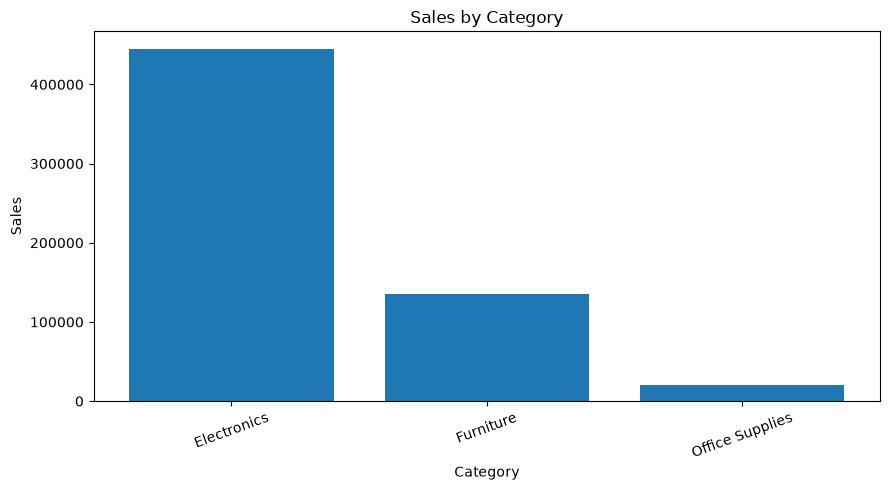

In [30]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(9,5))
plt.bar(category_sales.index, category_sales.values)
plt.xlabel("Category")
plt.ylabel("Sales")
plt.title("Sales by Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

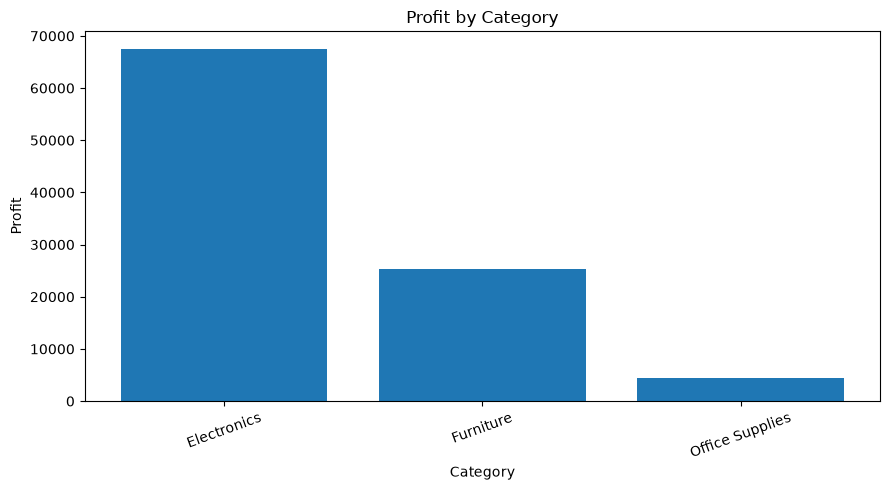

In [31]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

plt.figure(figsize=(9,5))
plt.bar(category_profit.index, category_profit.values)
plt.xlabel("Category")
plt.ylabel("Profit")
plt.title("Profit by Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

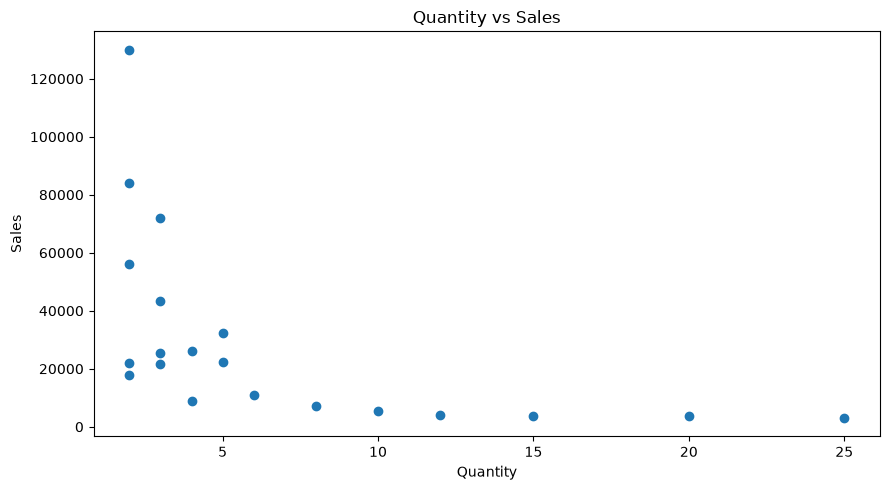

In [32]:
plt.figure(figsize=(9,5))
plt.scatter(df["Quantity"], df["Sales"])
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.title("Quantity vs Sales")
plt.tight_layout()
plt.show()

## Key Results

In [33]:
top_region = df.groupby("Region")["Sales"].sum().idxmax()
top_region_sales = df.groupby("Region")["Sales"].sum().max()

top_category = df.groupby("Category")["Sales"].sum().idxmax()
top_category_sales = df.groupby("Category")["Sales"].sum().max()

top_product = df.groupby("Product")["Sales"].sum().idxmax()
top_product_sales = df.groupby("Product")["Sales"].sum().max()

best_profit_product = df.loc[df["Profit"].idxmax(), "Product"]
best_profit = df["Profit"].max()

highest_month = df.groupby(df["OrderDate"].dt.to_period("M"))["Sales"].sum().idxmax()
highest_month_sales = df.groupby(df["OrderDate"].dt.to_period("M"))["Sales"].sum().max()

print("Total Sales:", df["Sales"].sum())
print("Average Sales:", df["Sales"].mean())
print("Highest Sales:", df["Sales"].max())
print("Lowest Sales:", df["Sales"].min())
print("Total Profit:", df["Profit"].sum())
print("Top Region:", top_region, "-", top_region_sales)
print("Top Category:", top_category, "-", top_category_sales)
print("Top Product:", top_product, "-", top_product_sales)
print("Highest Profit Product:", best_profit_product, "-", best_profit)
print("Best Sales Month:", highest_month, "-", highest_month_sales)

Total Sales: 600450
Average Sales: 30022.5
Highest Sales: 130000
Lowest Sales: 3000
Total Profit: 97300
Top Region: North - 213700
Top Category: Electronics - 444800
Top Product: Laptop - 130000
Highest Profit Product: Laptop - 18000
Best Sales Month: 2025-01 - 166800


In [34]:
insights = [
    f"{top_region} has the highest total sales.",
    f"{top_category} is the top-performing category by sales.",
    f"{top_product} is the highest-selling product.",
    f"{best_profit_product} generates the highest individual profit.",
    f"{highest_month} has the highest monthly sales.",
    f"The average order sales value is {df['Sales'].mean():.2f}.",
    f"The total profit across all orders is {df['Profit'].sum():.2f}."
]

for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

1. North has the highest total sales.
2. Electronics is the top-performing category by sales.
3. Laptop is the highest-selling product.
4. Laptop generates the highest individual profit.
5. 2025-01 has the highest monthly sales.
6. The average order sales value is 30022.50.
7. The total profit across all orders is 97300.00.
